In [1]:
import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from imblearn.combine import SMOTETomek
from lightgbm import LGBMClassifier

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Anchal's final temporal features
feature_df = pd.read_csv(
    "../data/features/anchal_seller_temporal_features_final.csv"
)

# Load our corrected seller risk labels
labels_df = pd.read_csv(
    "../data/processed/seller_risk_labels.csv"
)

# Convert date columns to datetime
feature_df["date"] = pd.to_datetime(feature_df["date"])
labels_df["date"] = pd.to_datetime(labels_df["date"])

print("Feature dataset shape:", feature_df.shape)
print("Label dataset shape:", labels_df.shape)

print("\nFeature columns:")
print(feature_df.columns.tolist())

print("\nLabel columns:")
print(labels_df.columns.tolist())

Feature dataset shape: (69413, 32)
Label dataset shape: (28974, 3)

Feature columns:
['seller_id', 'date', 'daily_order_count_rolling_7d', 'daily_order_count_rolling_30d', 'daily_order_count_rolling_90d', 'daily_sales_value_rolling_7d', 'daily_sales_value_rolling_30d', 'daily_sales_value_rolling_90d', 'average_delivery_delay_rolling_7d', 'average_delivery_delay_rolling_30d', 'average_delivery_delay_rolling_90d', 'late_delivery_rate_rolling_7d', 'late_delivery_rate_rolling_30d', 'late_delivery_rate_rolling_90d', 'average_review_score_rolling_7d', 'average_review_score_rolling_30d', 'average_review_score_rolling_90d', 'review_count_rolling_7d', 'review_count_rolling_30d', 'review_count_rolling_90d', 'daily_order_count_previous_7d', 'daily_order_count_change_vs_previous_7d', 'daily_order_count_previous_30d', 'daily_order_count_change_vs_previous_30d', 'daily_sales_value_previous_7d', 'daily_sales_value_change_vs_previous_7d', 'daily_sales_value_previous_30d', 'daily_sales_value_change_vs_

In [3]:
# Merge features with corrected risk labels
model_df = feature_df.merge(
    labels_df[["seller_id", "date", "risk_label"]],
    on=["seller_id", "date"],
    how="inner",
    validate="one_to_one"
)

print("Merged dataset shape:", model_df.shape)
print("\nRisk label distribution:")
print(model_df["risk_label"].value_counts().sort_index())

print("\nMissing risk labels:", model_df["risk_label"].isna().sum())
print(
    "Duplicate seller-date pairs:",
    model_df.duplicated(["seller_id", "date"]).sum()
)

Merged dataset shape: (28974, 33)

Risk label distribution:
risk_label
0    23427
1     5547
Name: count, dtype: int64

Missing risk labels: 0
Duplicate seller-date pairs: 0


In [4]:
# Separate input features and target variable
X = model_df.drop(columns=["seller_id", "date", "risk_label"])
y = model_df["risk_label"]

print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (28974, 30)
Target variable shape: (28974,)

Target distribution:
risk_label
0    23427
1     5547
Name: count, dtype: int64


In [5]:
# Define chronological split with a 30-day gap
split_date = model_df["date"].quantile(0.80)
train_end = split_date - pd.Timedelta(days=30)

train_mask = model_df["date"] < train_end
test_mask = model_df["date"] >= split_date

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Split date:", split_date)
print("Training end date:", model_df.loc[train_mask, "date"].max())
print("Testing start date:", model_df.loc[test_mask, "date"].min())

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting label distribution:")
print(y_test.value_counts().sort_index())

Split date: 2018-05-03 00:00:00
Training end date: 2018-04-02 00:00:00
Testing start date: 2018-05-03 00:00:00

Training records: 20940
Testing records: 5831

Training label distribution:
risk_label
0    16502
1     4438
Name: count, dtype: int64

Testing label distribution:
risk_label
0    5034
1     797
Name: count, dtype: int64


In [6]:
# Handle missing values using median imputation
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Training data shape after imputation:", X_train_imputed.shape)
print("Testing data shape after imputation:", X_test_imputed.shape)

print("Missing values in training data:", np.isnan(X_train_imputed).sum())
print("Missing values in testing data:", np.isnan(X_test_imputed).sum())

Training data shape after imputation: (20940, 30)
Testing data shape after imputation: (5831, 30)
Missing values in training data: 0
Missing values in testing data: 0


In [7]:
# Apply SMOTE-Tomek to training data only
smote_tomek = SMOTETomek(random_state=42)

X_train_resampled, y_train_resampled = smote_tomek.fit_resample(
    X_train_imputed,
    y_train
)

print("Training data before SMOTE-Tomek:")
print(y_train.value_counts().sort_index())

print("\nTraining data after SMOTE-Tomek:")
print(y_train_resampled.value_counts().sort_index())

print("\nResampled feature shape:", X_train_resampled.shape)
print("Resampled target shape:", y_train_resampled.shape)

print("\nOriginal test data shape:", X_test_imputed.shape)
print("Test data remains unchanged.")

Training data before SMOTE-Tomek:
risk_label
0    16502
1     4438
Name: count, dtype: int64

Training data after SMOTE-Tomek:
risk_label
0    16170
1    16170
Name: count, dtype: int64

Resampled feature shape: (32340, 30)
Resampled target shape: (32340,)

Original test data shape: (5831, 30)
Test data remains unchanged.


In [8]:
# Initialize LightGBM Classifier
model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train the model
model.fit(X_train_resampled, y_train_resampled)

print("LightGBM model trained successfully!")

LightGBM model trained successfully!


In [9]:
# Predict class labels and probabilities
y_pred = model.predict(X_test_imputed)
y_pred_proba = model.predict_proba(X_test_imputed)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_proba)
pr_auc = average_precision_score(y_test, y_pred_proba)

print("LIGHTGBM MODEL EVALUATION")
print("-------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print(f"\nTest-set positive-class baseline: {y_test.mean():.4f}")

LIGHTGBM MODEL EVALUATION
-------------------------
Accuracy:  0.6309
Precision: 0.1275
Recall:    0.2911
F1-score:  0.1774
ROC-AUC:   0.4887
PR-AUC:    0.1446

Confusion Matrix:
[[3447 1587]
 [ 565  232]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.68      0.76      5034
           1       0.13      0.29      0.18       797

    accuracy                           0.63      5831
   macro avg       0.49      0.49      0.47      5831
weighted avg       0.76      0.63      0.68      5831


Test-set positive-class baseline: 0.1367


In [10]:
# Train a comparison LightGBM model without SMOTE-Tomek
baseline_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

baseline_model.fit(X_train_imputed, y_train)

# Predict probabilities on the same test data
baseline_probabilities = baseline_model.predict_proba(X_test_imputed)[:, 1]

# Evaluate PR-AUC and ROC-AUC
baseline_pr_auc = average_precision_score(
    y_test, baseline_probabilities
)
baseline_roc_auc = roc_auc_score(
    y_test, baseline_probabilities
)

print("LIGHTGBM WITHOUT SMOTE-TOMEK")
print("----------------------------")
print(f"PR-AUC:  {baseline_pr_auc:.4f}")
print(f"ROC-AUC: {baseline_roc_auc:.4f}")

print("\nCOMPARISON")
print("----------------------------")
print(f"With SMOTE-Tomek PR-AUC:    {pr_auc:.4f}")
print(f"Without SMOTE-Tomek PR-AUC: {baseline_pr_auc:.4f}")

LIGHTGBM WITHOUT SMOTE-TOMEK
----------------------------
PR-AUC:  0.1449
ROC-AUC: 0.4958

COMPARISON
----------------------------
With SMOTE-Tomek PR-AUC:    0.1446
Without SMOTE-Tomek PR-AUC: 0.1449


In [11]:
# Extract LightGBM feature importance
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
print(importance_df.head(15).to_string(index=False))

TOP 15 IMPORTANT FEATURES
                                Feature  Importance
                review_count_rolling_7d         566
       average_review_score_rolling_90d         540
         late_delivery_rate_rolling_90d         533
               review_count_rolling_90d         514
     average_delivery_delay_rolling_90d         508
          daily_sales_value_rolling_90d         466
daily_order_count_change_vs_previous_7d         437
               review_count_rolling_30d         404
     average_delivery_delay_rolling_30d         385
         daily_order_count_previous_30d         350
         daily_sales_value_previous_30d         342
      average_review_score_previous_30d         329
          daily_sales_value_rolling_30d         295
          daily_order_count_rolling_90d         288
           daily_order_count_rolling_7d         285


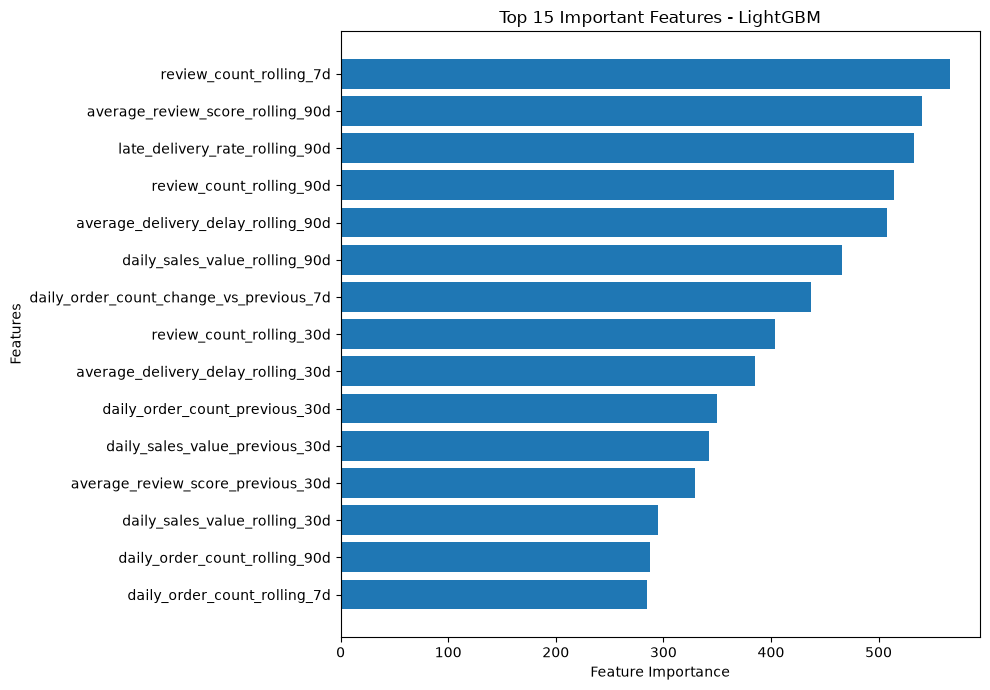

In [14]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - LightGBM")
plt.tight_layout()
plt.show()

In [13]:
%pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 262.6 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 560.2 kB/s eta 0:00:00
     ---------------------------------------- 0.0/139.8 kB ? eta -:--:--
     ---------------------- ---------------- 81.9/139.8 kB 2.3 MB/s eta 0:00:01
     -------------------------------------- 139.8/139.8 kB 1.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/9.3 MB 2.0 MB/s eta 0:00:05
    --------------------------------------- 0.2/9.3 MB 2.1 MB/s eta 0:00:05
   - -------------------------------------- 0.3/9.3 MB 2.1 MB/s eta 0:00:05
   - -------------------------------------- 0.4/9.3 MB 2.1 MB/s eta 0:00:05
   -- ----------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
# Check feature statistics
print("FEATURE STATISTICS")
print("------------------")
display(X.describe().T)

print("\nFeatures with zero variance:")
zero_variance = X.columns[X.nunique() <= 1].tolist()
print(zero_variance)

print("\nTotal features:", X.shape[1])
print("Zero-variance features:", len(zero_variance))

FEATURE STATISTICS
------------------


,count,mean,std,min,25%,50%,75%,max
daily_order_count_rolling_7d,28494.0,8.423879,9.566860,0.000000,3.000000,5.000000,11.000000,181.000000
daily_order_count_rolling_30d,28767.0,32.683735,34.952662,0.000000,11.000000,21.000000,39.000000,290.000000
daily_order_count_rolling_90d,28801.0,87.383146,96.742170,0.000000,27.000000,53.000000,103.000000,572.000000
daily_sales_value_rolling_7d,28494.0,966.961358,1532.779678,0.000000,189.500000,479.695000,1183.975000,56787.600000
daily_sales_value_rolling_30d,28767.0,3704.272278,5088.935216,0.000000,847.350000,1910.950000,4612.150000,93105.600000
daily_sales_value_rolling_90d,28801.0,9784.900841,12908.565396,0.000000,2126.000000,4876.200000,11969.300000,157271.520000
average_delivery_delay_rolling_7d,26396.0,-11.612817,6.436049,-54.244722,-14.702143,-11.447769,-8.175314,88.596632
average_delivery_delay_rolling_30d,28152.0,-11.937703,5.270913,-49.364919,-14.226289,-11.503733,-8.980238,33.491354
average_delivery_delay_rolling_90d,28310.0,-12.151630,4.733580,-57.261586,-13.834509,-11.392392,-9.345763,21.893877
late_delivery_rate_rolling_7d,26396.0,0.069555,0.155604,0.000000,0.000000,0.000000,0.062500,1.000000



Features with zero variance:
[]

Total features: 30
Zero-variance features: 0


In [16]:
# Compare feature medians across risk groups
feature_comparison = model_df.groupby("risk_label")[X.columns].median().T

feature_comparison.columns = [
    "Lower_Risk (0)",
    "Higher_Risk (1)"
]

feature_comparison["Difference"] = (
    feature_comparison["Higher_Risk (1)"]
    - feature_comparison["Lower_Risk (0)"]
)

feature_comparison["Absolute_Difference"] = (
    feature_comparison["Difference"].abs()
)

feature_comparison = feature_comparison.sort_values(
    by="Absolute_Difference",
    ascending=False
)

display(feature_comparison.head(15))

,Lower_Risk (0),Higher_Risk (1),Difference,Absolute_Difference
daily_sales_value_previous_30d,1771.810000,1577.100000,-194.710000,194.710000
daily_sales_value_rolling_90d,4900.960000,4733.430000,-167.530000,167.530000
daily_sales_value_rolling_30d,1926.400000,1849.050000,-77.350000,77.350000
daily_sales_value_change_vs_previous_30d,169.600000,245.800000,76.200000,76.200000
daily_sales_value_previous_7d,436.000000,399.460000,-36.540000,36.540000
daily_sales_value_change_vs_previous_7d,22.990000,34.950000,11.960000,11.960000
daily_order_count_rolling_90d,54.000000,47.000000,-7.000000,7.000000
review_count_rolling_90d,50.000000,43.000000,-7.000000,7.000000
daily_sales_value_rolling_7d,479.400000,482.470000,3.070000,3.070000
review_count_rolling_30d,20.000000,17.000000,-3.000000,3.000000


In [18]:
# Train LightGBM using balanced class weights
weighted_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

weighted_model.fit(X_train_imputed, y_train)

# Predict probabilities on the untouched test set
weighted_probabilities = weighted_model.predict_proba(
    X_test_imputed
)[:, 1]

# Evaluate
weighted_pr_auc = average_precision_score(
    y_test, weighted_probabilities
)
weighted_roc_auc = roc_auc_score(
    y_test, weighted_probabilities
)

print("CLASS-WEIGHTED LIGHTGBM")
print("-----------------------")
print(f"PR-AUC:  {weighted_pr_auc:.4f}")
print(f"ROC-AUC: {weighted_roc_auc:.4f}")

print("\nMODEL COMPARISON")
print("-----------------------")
print(f"SMOTE-Tomek:       {pr_auc:.4f}")
print(f"Without SMOTE:     {baseline_pr_auc:.4f}")
print(f"Class-weighted:    {weighted_pr_auc:.4f}")
print(f"Test baseline:     {y_test.mean():.4f}")

CLASS-WEIGHTED LIGHTGBM
-----------------------
PR-AUC:  0.1545
ROC-AUC: 0.5092

MODEL COMPARISON
-----------------------
SMOTE-Tomek:       0.1446
Without SMOTE:     0.1449
Class-weighted:    0.1545
Test baseline:     0.1367


,Model,PR-AUC
0,SMOTE-Tomek LightGBM,0.144582
1,LightGBM without SMOTE,0.144883
2,Class-weighted LightGBM,0.154500


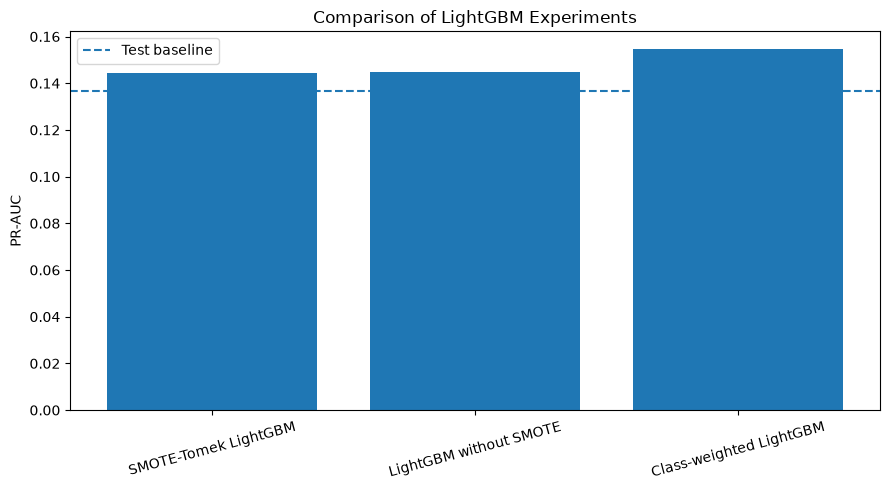

In [19]:
# Compare PR-AUC scores of all three models
comparison_df = pd.DataFrame({
    "Model": [
        "SMOTE-Tomek LightGBM",
        "LightGBM without SMOTE",
        "Class-weighted LightGBM"
    ],
    "PR-AUC": [
        pr_auc,
        baseline_pr_auc,
        weighted_pr_auc
    ]
})

display(comparison_df)

plt.figure(figsize=(9, 5))
plt.bar(comparison_df["Model"], comparison_df["PR-AUC"])

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Test baseline"
)

plt.ylabel("PR-AUC")
plt.title("Comparison of LightGBM Experiments")
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Evaluate the class-weighted LightGBM model
weighted_predictions = weighted_model.predict(X_test_imputed)

print("CLASS-WEIGHTED LIGHTGBM EVALUATION")
print("----------------------------------")

print(f"Accuracy:  {accuracy_score(y_test, weighted_predictions):.4f}")
print(f"Precision: {precision_score(y_test, weighted_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, weighted_predictions, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, weighted_predictions, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, weighted_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    weighted_predictions,
    zero_division=0
))

CLASS-WEIGHTED LIGHTGBM EVALUATION
----------------------------------
Accuracy:  0.5167
Precision: 0.1377
Recall:    0.4818
F1-score:  0.2142

Confusion Matrix:
[[2629 2405]
 [ 413  384]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.52      0.65      5034
           1       0.14      0.48      0.21       797

    accuracy                           0.52      5831
   macro avg       0.50      0.50      0.43      5831
weighted avg       0.76      0.52      0.59      5831



In [21]:
import os
import joblib

# Create model output directory
os.makedirs("../models", exist_ok=True)

# Save class-weighted LightGBM model
joblib.dump(
    weighted_model,
    "../models/seller_risk_lightgbm.pkl"
)

# Save fitted median imputer
joblib.dump(
    imputer,
    "../models/seller_risk_imputer.pkl"
)

print("Model and imputer saved successfully!")

Model and imputer saved successfully!


In [22]:
# Prepare test-set predictions for Member 4
predictions_df = model_df.loc[
    test_mask, ["seller_id", "date", "risk_label"]
].copy()

predictions_df["predicted_risk_probability"] = weighted_probabilities
predictions_df["predicted_risk_label"] = weighted_predictions

# Save predictions
os.makedirs("../data/processed", exist_ok=True)

predictions_df.to_csv(
    "../data/processed/seller_risk_predictions.csv",
    index=False
)

print("Predictions saved successfully!")
print("Prediction dataset shape:", predictions_df.shape)
print("\nFirst 5 predictions:")
display(predictions_df.head())

Predictions saved successfully!
Prediction dataset shape: (5831, 5)

First 5 predictions:


,seller_id,date,risk_label,predicted_risk_probability,predicted_risk_label
323,01fd077212124329bac32490e8ef80d9,2018-07-23,0,0.393927,0
324,01fd077212124329bac32490e8ef80d9,2018-08-04,0,0.600577,1
344,01fdefa7697d26ad920e9e0346d4bd1b,2018-07-19,0,0.494491,0
345,01fdefa7697d26ad920e9e0346d4bd1b,2018-07-24,0,0.511164,1
346,01fdefa7697d26ad920e9e0346d4bd1b,2018-07-26,0,0.493834,0


In [23]:
# Verify saved model artifacts and predictions
required_files = [
    "../models/seller_risk_lightgbm.pkl",
    "../models/seller_risk_imputer.pkl",
    "../data/processed/seller_risk_predictions.csv"
]

for file_path in required_files:
    print(
        file_path,
        "EXISTS" if os.path.exists(file_path) else "MISSING"
    )

print("\nPrediction records:", len(predictions_df))
print(
    "Missing prediction probabilities:",
    predictions_df["predicted_risk_probability"].isna().sum()
)


../models/seller_risk_lightgbm.pkl EXISTS
../models/seller_risk_imputer.pkl EXISTS
../data/processed/seller_risk_predictions.csv EXISTS

Prediction records: 5831
Missing prediction probabilities: 0
